# 02. Thực nghiệm So sánh Luồng tiền xử lý & Các Mô hình Học máy
**Nhóm 12 — Đề tài 12:** Phát hiện giao dịch thẻ tín dụng gian lận  
**Mục tiêu:**
1. Thiết lập chia dữ liệu `Train / Validation / Test` (60/20/20, `random_state=42`) **trước khi** `fit` mọi bộ chuẩn hóa để loại bỏ data leakage.
2. So sánh **Luồng A (Pipeline cơ bản)** và **Luồng B (Pipeline cải tiến)** trả lời câu hỏi: *Thay đổi cách chuẩn bị dữ liệu có làm thay đổi hiệu quả mô hình không, và tại sao?*
3. Huấn luyện & tinh chỉnh tham số cho **Baseline**, 3 thuật toán đã học (**K-NN, Gaussian Naive Bayes, Decision Tree**), cùng kỹ thuật mở rộng (**Random Forest, HistGradientBoosting**, **Threshold Tuning**, và **Time-based Split**).

In [1]:
import sys, json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_creditcard_data
from src.preprocessing import prepare_flow_a, prepare_flow_b

df = load_creditcard_data()
flow_a = prepare_flow_a(df, split_strategy="stratified", scale=True, random_state=42)
flow_b = prepare_flow_b(df, split_strategy="stratified", scaler_type="robust", random_state=42)

print("Flow A metadata:", flow_a.metadata)
print("Flow A shapes (Train/Val/Test):", flow_a.X_train.shape, flow_a.X_val.shape, flow_a.X_test.shape)
print("Flow B metadata:", flow_b.metadata)
print("Flow B shapes (Train/Val/Test):", flow_b.X_train.shape, flow_b.X_val.shape, flow_b.X_test.shape)

Flow A metadata: {'deduplicated': False, 'n_rows_used': 284807, 'split_strategy': 'stratified', 'scaler': 'StandardScaler'}
Flow A shapes (Train/Val/Test): (170883, 30) (56962, 30) (56962, 30)
Flow B metadata: {'deduplicated': True, 'duplicates_removed': 1081, 'n_rows_used': 283726, 'split_strategy': 'stratified', 'scaler': 'robust'}
Flow B shapes (Train/Val/Test): (170235, 32) (56745, 32) (56746, 32)


### Kiểm chứng tách tập và chống rò rỉ dữ liệu
- **Luồng A** giữ toàn bộ `284,807` mẫu với 30 đặc trưng gốc (`Time, V1..V28, Amount`), chia Stratified `60/20/20` (`170,883 / 56,962 / 56,962`) và chỉ `fit(StandardScaler)` trên tập Train.
- **Luồng B** loại bỏ **1.081 dòng trùng lặp** trước khi chia (`283,726` mẫu còn lại -> `170,235 / 56,745 / 56,746`), bổ sung `Hour_sin`, `Hour_cos`, `Log_Amount = log1p(Amount)`, `Is_Zero_Amount` (32 đặc trưng, loại bỏ `Time` thô), và dùng `RobustScaler` fit riêng trên Train.

Cấu hình tốt nhất trên Validation (Luồng B):
{
  "random_state": 42,
  "flow_a_meta": {
    "deduplicated": false,
    "n_rows_used": 284807,
    "split_strategy": "stratified",
    "scaler": "StandardScaler"
  },
  "flow_b_meta": {
    "deduplicated": true,
    "duplicates_removed": 1081,
    "n_rows_used": 283726,
    "split_strategy": "stratified",
    "scaler": "robust"
  },
  "best_knn": {
    "n_neighbors": 3,
    "weights": "distance",
    "metric": "euclidean"
  },
  "best_decision_tree": {
    "criterion": "entropy",
    "max_depth": 6,
    "min_samples_leaf": 5,
    "class_weight": null
  },
  "best_naive_bayes": {
    "var_smoothing": 0.1,
    "scaler": "robust"
  }
}


,family,variant,param_name,param_val,val_precision,val_recall,val_f1,val_pr_auc
0,K-NN,weights=uniform,n_neighbors,3.000000e+00,0.9070,0.8298,0.8667,0.8141
1,K-NN,weights=uniform,n_neighbors,5.000000e+00,0.9259,0.7979,0.8571,0.8073
2,K-NN,weights=uniform,n_neighbors,7.000000e+00,0.9231,0.7660,0.8372,0.8119
3,K-NN,weights=uniform,n_neighbors,1.100000e+01,0.9221,0.7553,0.8304,0.8030
4,K-NN,weights=distance,n_neighbors,3.000000e+00,0.9398,0.8298,0.8814,0.8244
5,K-NN,weights=distance,n_neighbors,5.000000e+00,0.9167,0.8191,0.8652,0.8213
6,K-NN,weights=distance,n_neighbors,7.000000e+00,0.9268,0.8085,0.8636,0.8265
7,K-NN,weights=distance,n_neighbors,1.100000e+01,0.9146,0.7979,0.8523,0.8240
8,Decision Tree,class_weight=None,max_depth,4.000000e+00,0.8351,0.8617,0.8482,0.8031
9,Decision Tree,class_weight=None,max_depth,6.000000e+00,0.8681,0.8404,0.8541,0.8230


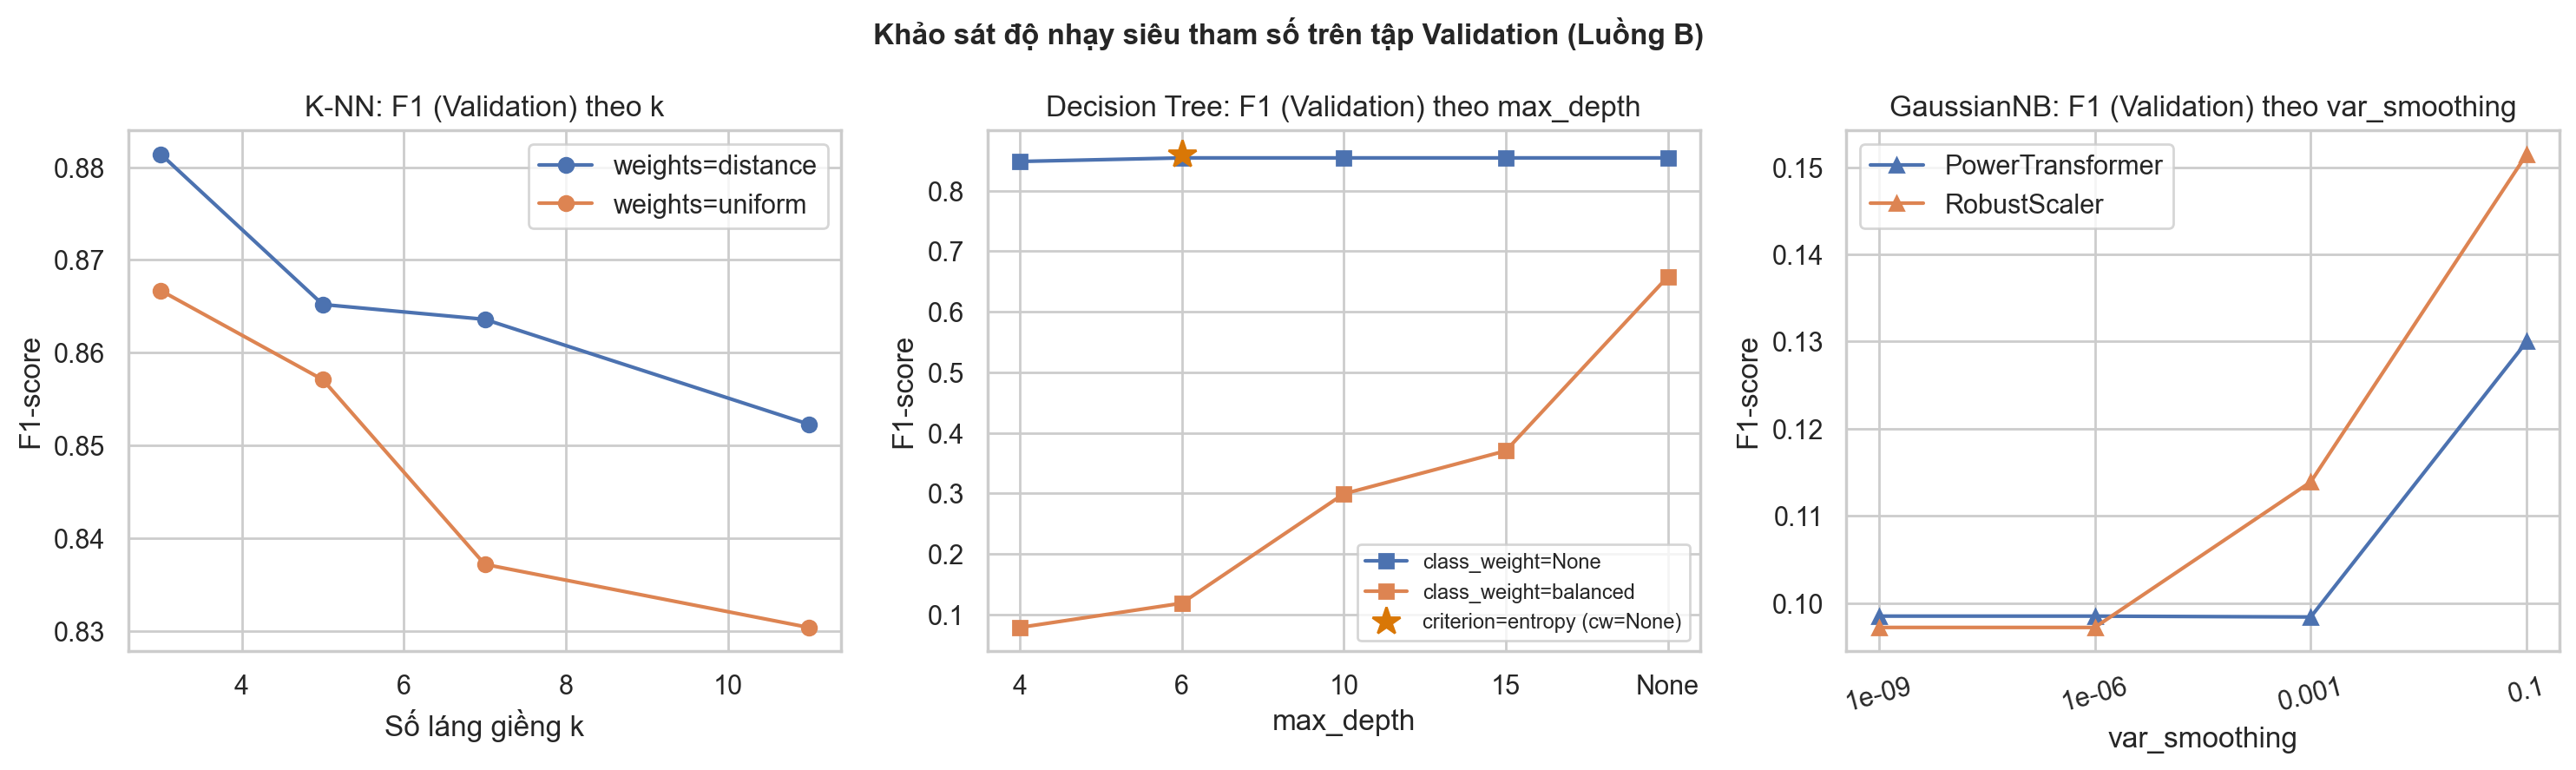

In [2]:
tuning_df = pd.read_csv(PROJECT_ROOT / "outputs" / "metrics" / "tuning_results.csv")
with (PROJECT_ROOT / "outputs" / "metrics" / "best_configs.json").open("r", encoding="utf-8") as f:
    best_cfg = json.load(f)

print("Cấu hình tốt nhất trên Validation (Luồng B):")
print(json.dumps(best_cfg, indent=2, ensure_ascii=False))
display(tuning_df)

fig_tune = PROJECT_ROOT / "outputs" / "figures" / "hyperparameter_sensitivity.png"
if fig_tune.is_file():
    display(Image(filename=str(fig_tune)))

### Phân tích độ nhạy siêu tham số trên Validation (Luồng B)
- **K-NN:** Khi giảm `k` xuống `3` và dùng `weights="distance"`, `val_f1` đạt đỉnh **0.8814** (`val_precision=0.9398`, `val_recall=0.8298`, `val_pr_auc=0.8244`). Tăng `k` lên `7` hay `11` làm ranh giới bị làm mịn quá mức khiến các cụm gian lận nhỏ bị láng giềng hợp lệ áp đảo, làm giảm Recall từ `0.8298` xuống `0.7553` (`uniform`).
- **Decision Tree:** Sự tương phản rất rõ giữa `class_weight=None` (`val_f1=0.8541` ở `max_depth=6`) và `class_weight="balanced"` (`val_f1=0.0788` tại `depth=4` và `0.1188` tại `depth=6`). Do tỉ lệ mất cân bằng ~578:1, gán `balanced` ép các lá cây nông gán nhãn gian lận quá mức (Precision chỉ `0.0637`). Khi dùng `criterion="entropy"`, `max_depth=6`, `class_weight=None`, mô hình đạt `val_f1=0.8603`.
- **Gaussian Naive Bayes:** Tăng `var_smoothing` lên `0.1` giúp làm trơn phương sai ước lượng và cải thiện `val_f1` trên `RobustScaler` từ `0.0972` lên **0.1515** (`val_pr_auc=0.1081`).

In [3]:
results_df = pd.read_csv(PROJECT_ROOT / "outputs" / "metrics" / "model_comparison.csv")
cols = ["flow", "model", "threshold", "accuracy", "precision", "recall", "f1", "pr_auc", "roc_auc", "fp", "fn", "tp", "fit_time_sec", "predict_time_sec"]
display(results_df[cols])

,flow,model,threshold,accuracy,precision,recall,f1,pr_auc,roc_auc,fp,fn,tp,fit_time_sec,predict_time_sec
0,Flow A (Cơ bản),Baseline: Dummy (Most Frequent),0.50,0.9983,0.0000,0.0000,0.0000,0.0017,0.5000,0,98,0,0.007,0.000
1,Flow A (Cơ bản),Baseline: Decision Tree (Mặc định),0.50,0.9991,0.7400,0.7551,0.7475,0.5592,0.8773,26,24,74,9.279,0.007
2,Flow A (Chưa chuẩn hóa),"K-NN (k=5, Unscaled)",0.50,0.9983,1.0000,0.0306,0.0594,0.0826,0.5953,0,95,3,0.018,9.889
3,Flow A (Cơ bản),K-NN (k=5),0.50,0.9995,0.9146,0.7653,0.8333,0.8094,0.9335,7,23,75,0.029,8.612
4,Flow A (Cơ bản),Gaussian Naive Bayes,0.50,0.9762,0.0583,0.8469,0.1091,0.0798,0.9630,1340,15,83,0.071,0.027
5,Flow A (Cơ bản),Decision Tree (Tuned),0.50,0.9917,0.1516,0.8367,0.2567,0.5582,0.9053,459,16,82,3.388,0.005
6,Flow A (Cơ bản),Random Forest (Mở rộng),0.50,0.9994,0.8837,0.7755,0.8261,0.8396,0.9694,10,22,76,10.781,0.076
7,Flow A (Cơ bản),HistGradientBoosting (Mở rộng),0.50,0.9979,0.4503,0.8776,0.5952,0.7289,0.9691,105,12,86,14.395,0.048
8,Flow B (Cải tiến),K-NN (Tuned),0.50,0.9994,0.9429,0.6947,0.8000,0.7446,0.8788,4,29,66,0.016,9.079
9,Flow B (Cải tiến),K-NN (Tuned) (Threshold=0.55),0.55,0.9994,0.9412,0.6737,0.7853,0.7446,0.8788,4,31,64,0.016,9.079


### Diễn giải Bảng kết quả Tổng hợp trên Tập Test
1. **Minh chứng Accuracy gây hiểu nhầm:** `Baseline: Dummy (Most Frequent)` đạt `Accuracy = 0.9983` nhưng `Recall = 0.0000`, `F1 = 0.0000`, `PR-AUC = 0.0017`.
2. **Tác động cực mạnh của chuẩn hóa đối với K-NN:** Ở `Flow A (Chưa chuẩn hóa)`, `K-NN (k=5)` chỉ đạt `Recall = 0.0306` (`3/98` ca, `F1 = 0.0594`) do `Time` và `Amount` lấn át khoảng cách Euclidean. Sau khi chuẩn hóa ở Luồng A, `F1` tăng vọt lên **0.8333**.
3. **Bằng chứng phát hiện rò rỉ trùng lặp giữa Luồng A và Luồng B:** Ở Luồng A (chưa khử 1.081 dòng trùng lặp), K-NN đạt `Recall = 0.7653` (`F1 = 0.8333`) phần nào nhờ ghi nhớ các mẫu gian lận trùng lặp nằm rải ở cả Train và Test. Khi khử trùng lặp ở **Luồng B**, `K-NN (Tuned)` phản ánh năng lực tổng quát hóa trung thực hơn với **`Precision = 0.9429`** (chỉ 4 báo nhầm) và `F1 = 0.8000`. Trong khi đó, **Decision Tree (Tuned)** ở Luồng B cải thiện ngoạn mục từ `F1 = 0.2567` (Luồng A, `459` FP) lên **`F1 = 0.7578`** (chỉ `5` FP).
4. **Đánh đổi của Undersampling trên Train (`K-NN Undersample 10:1`):** Thời gian suy luận giảm gần **45 lần** (`9.079s -> 0.203s`) và `Recall` tăng từ `0.6947` lên **`0.7368`**, nhưng `Precision` giảm mạnh xuống `0.3030` (`161` FP).
5. **Kỹ thuật mở rộng (Ensemble + Threshold Tuning) & Kiểm chứng Time-Split:**
   - **`Random Forest (Mở rộng)`** kết hợp tối ưu ngưỡng trên Validation (`Threshold = 0.55`) đạt kết quả tổng thể tốt nhất trên Luồng B: **`F1 = 0.8193`**, **`Precision = 0.9577`** (chỉ **3 FP**), **`Recall = 0.7158`**, **`PR-AUC = 0.8014`**.
   - **`HistGradientBoosting (Mở rộng)`** sau Threshold Tuning (`0.50 -> 0.90` trên Validation) tăng Precision từ `0.4740` lên **`0.8500`** và `F1` từ `0.5863` lên **`0.7771`**.
   - Trên **`Flow B (Chia theo Time)`**, `K-NN` (`F1=0.8060`) và `Random Forest` (`F1=0.8031`, `PR-AUC=0.8056`, `ROC-AUC=0.9517`) vẫn giữ vững hiệu năng khi kiểm thử trên khung giờ tương lai.

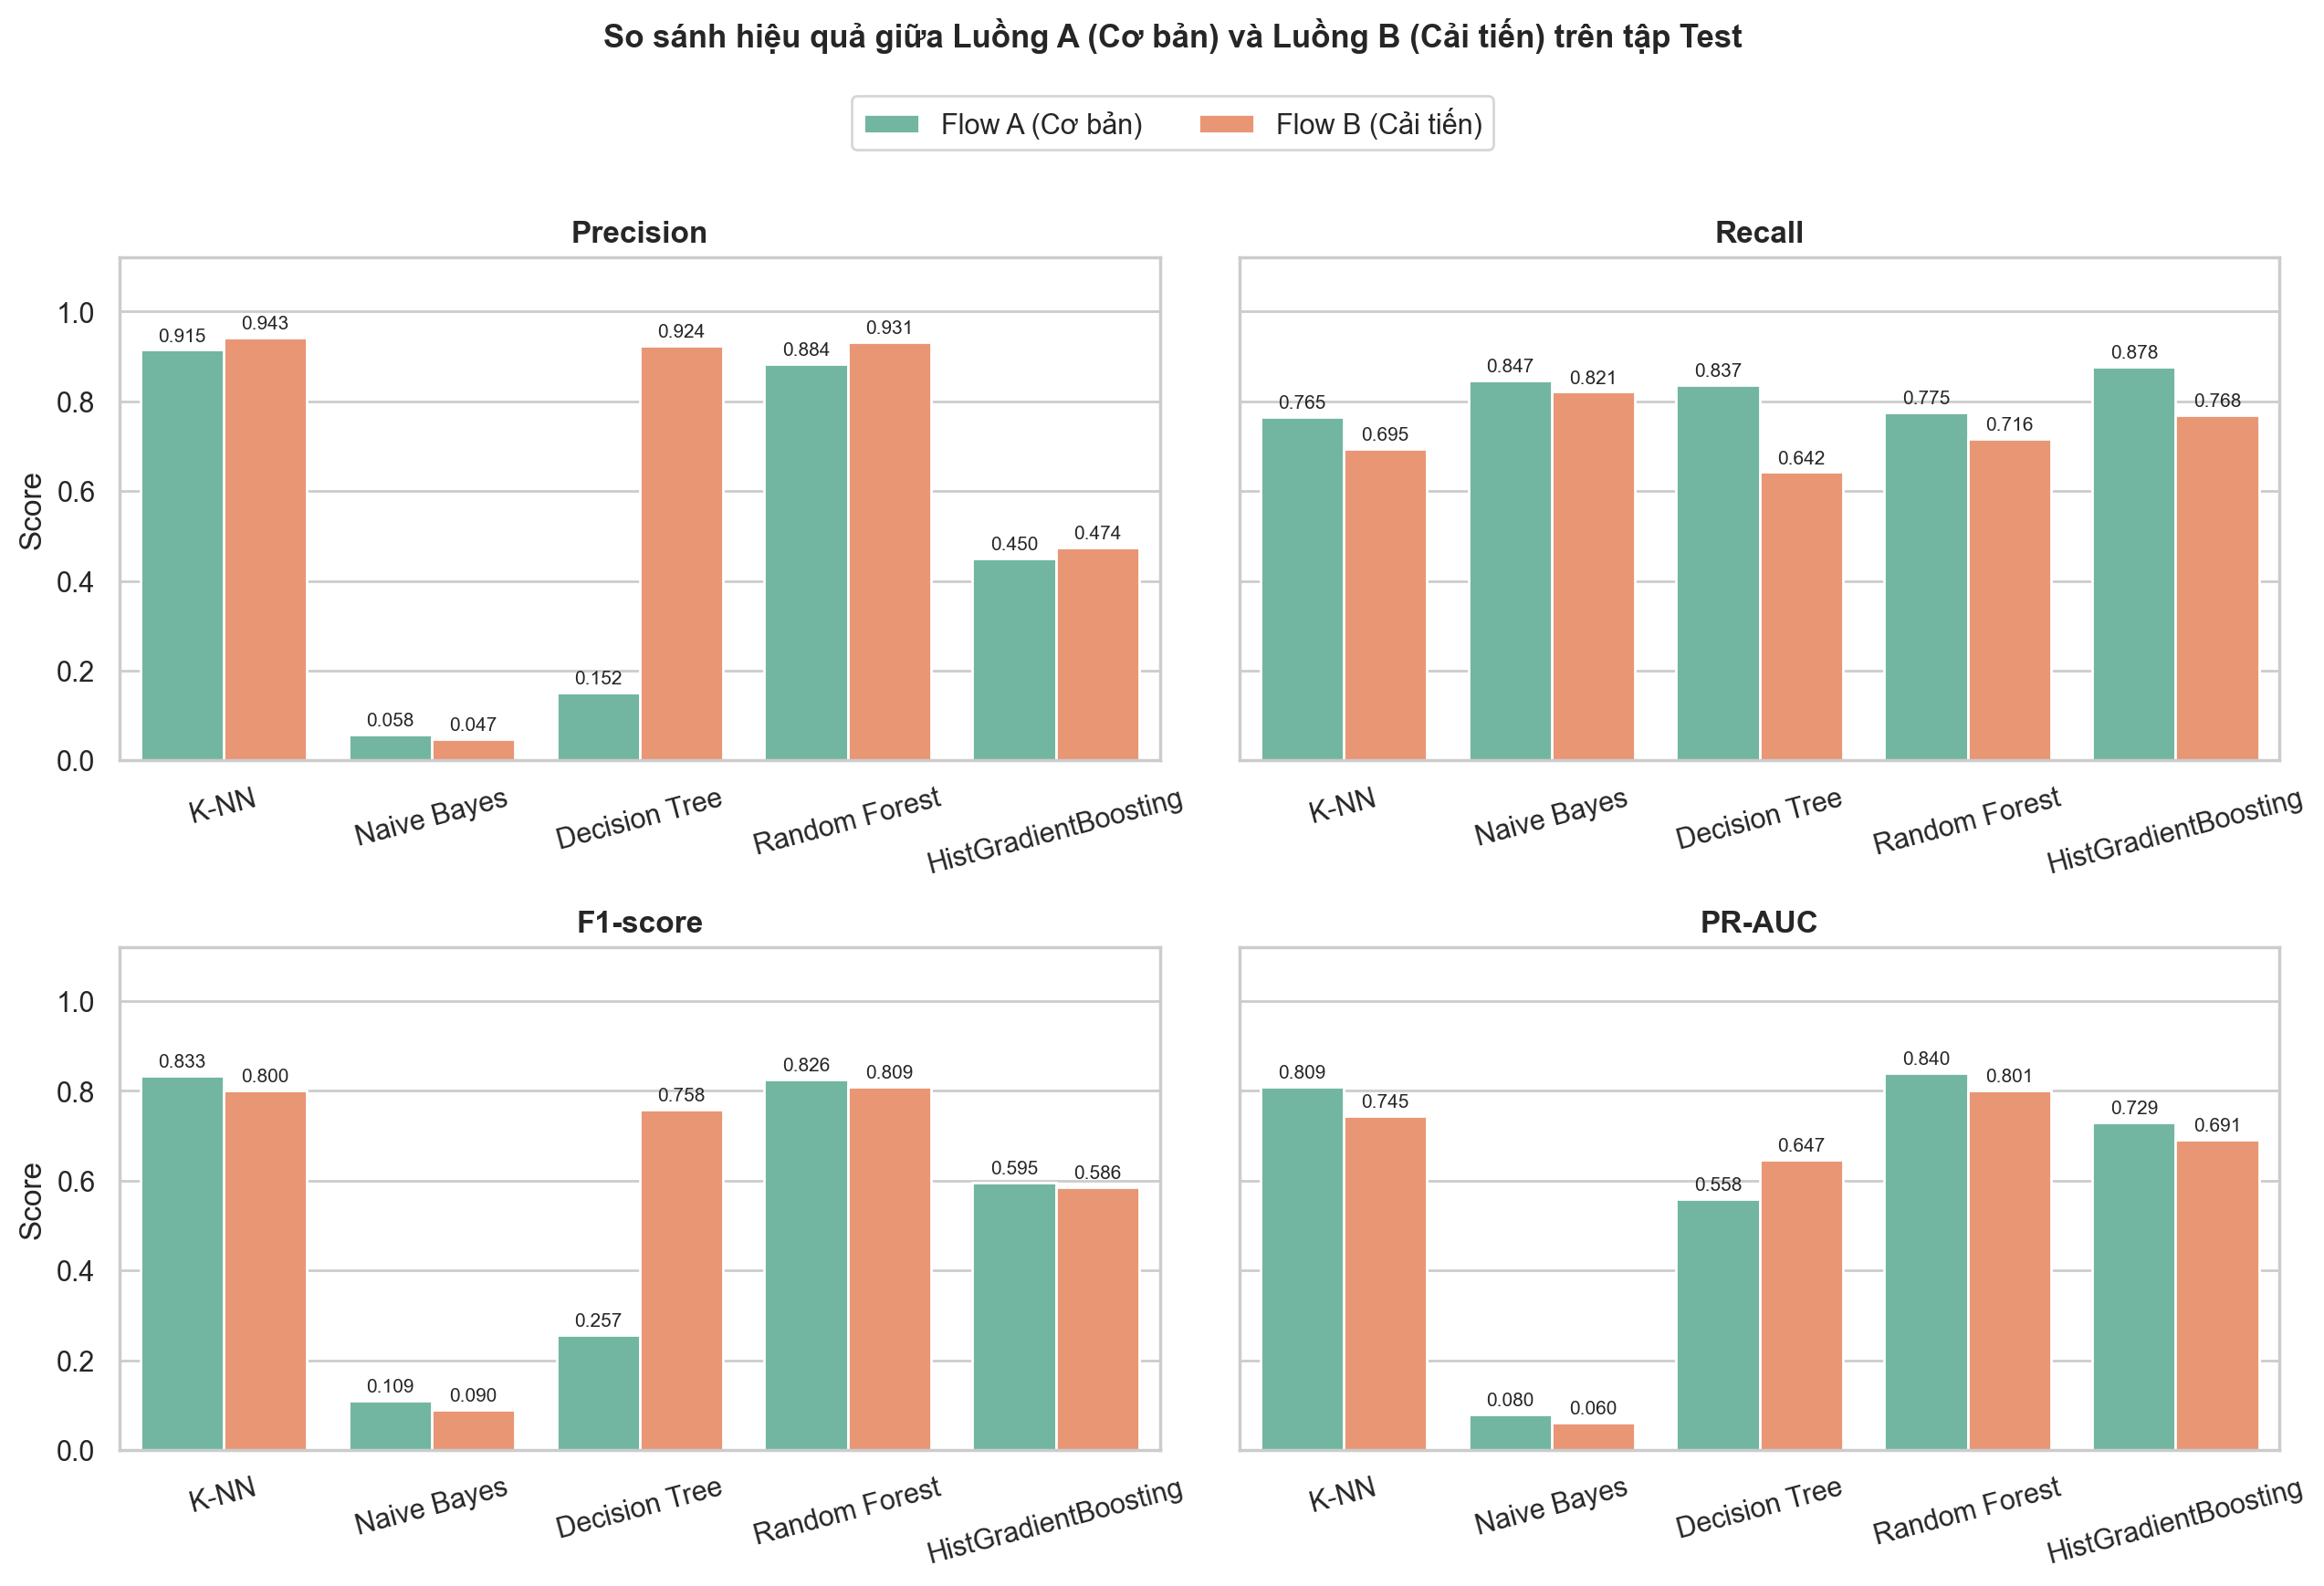

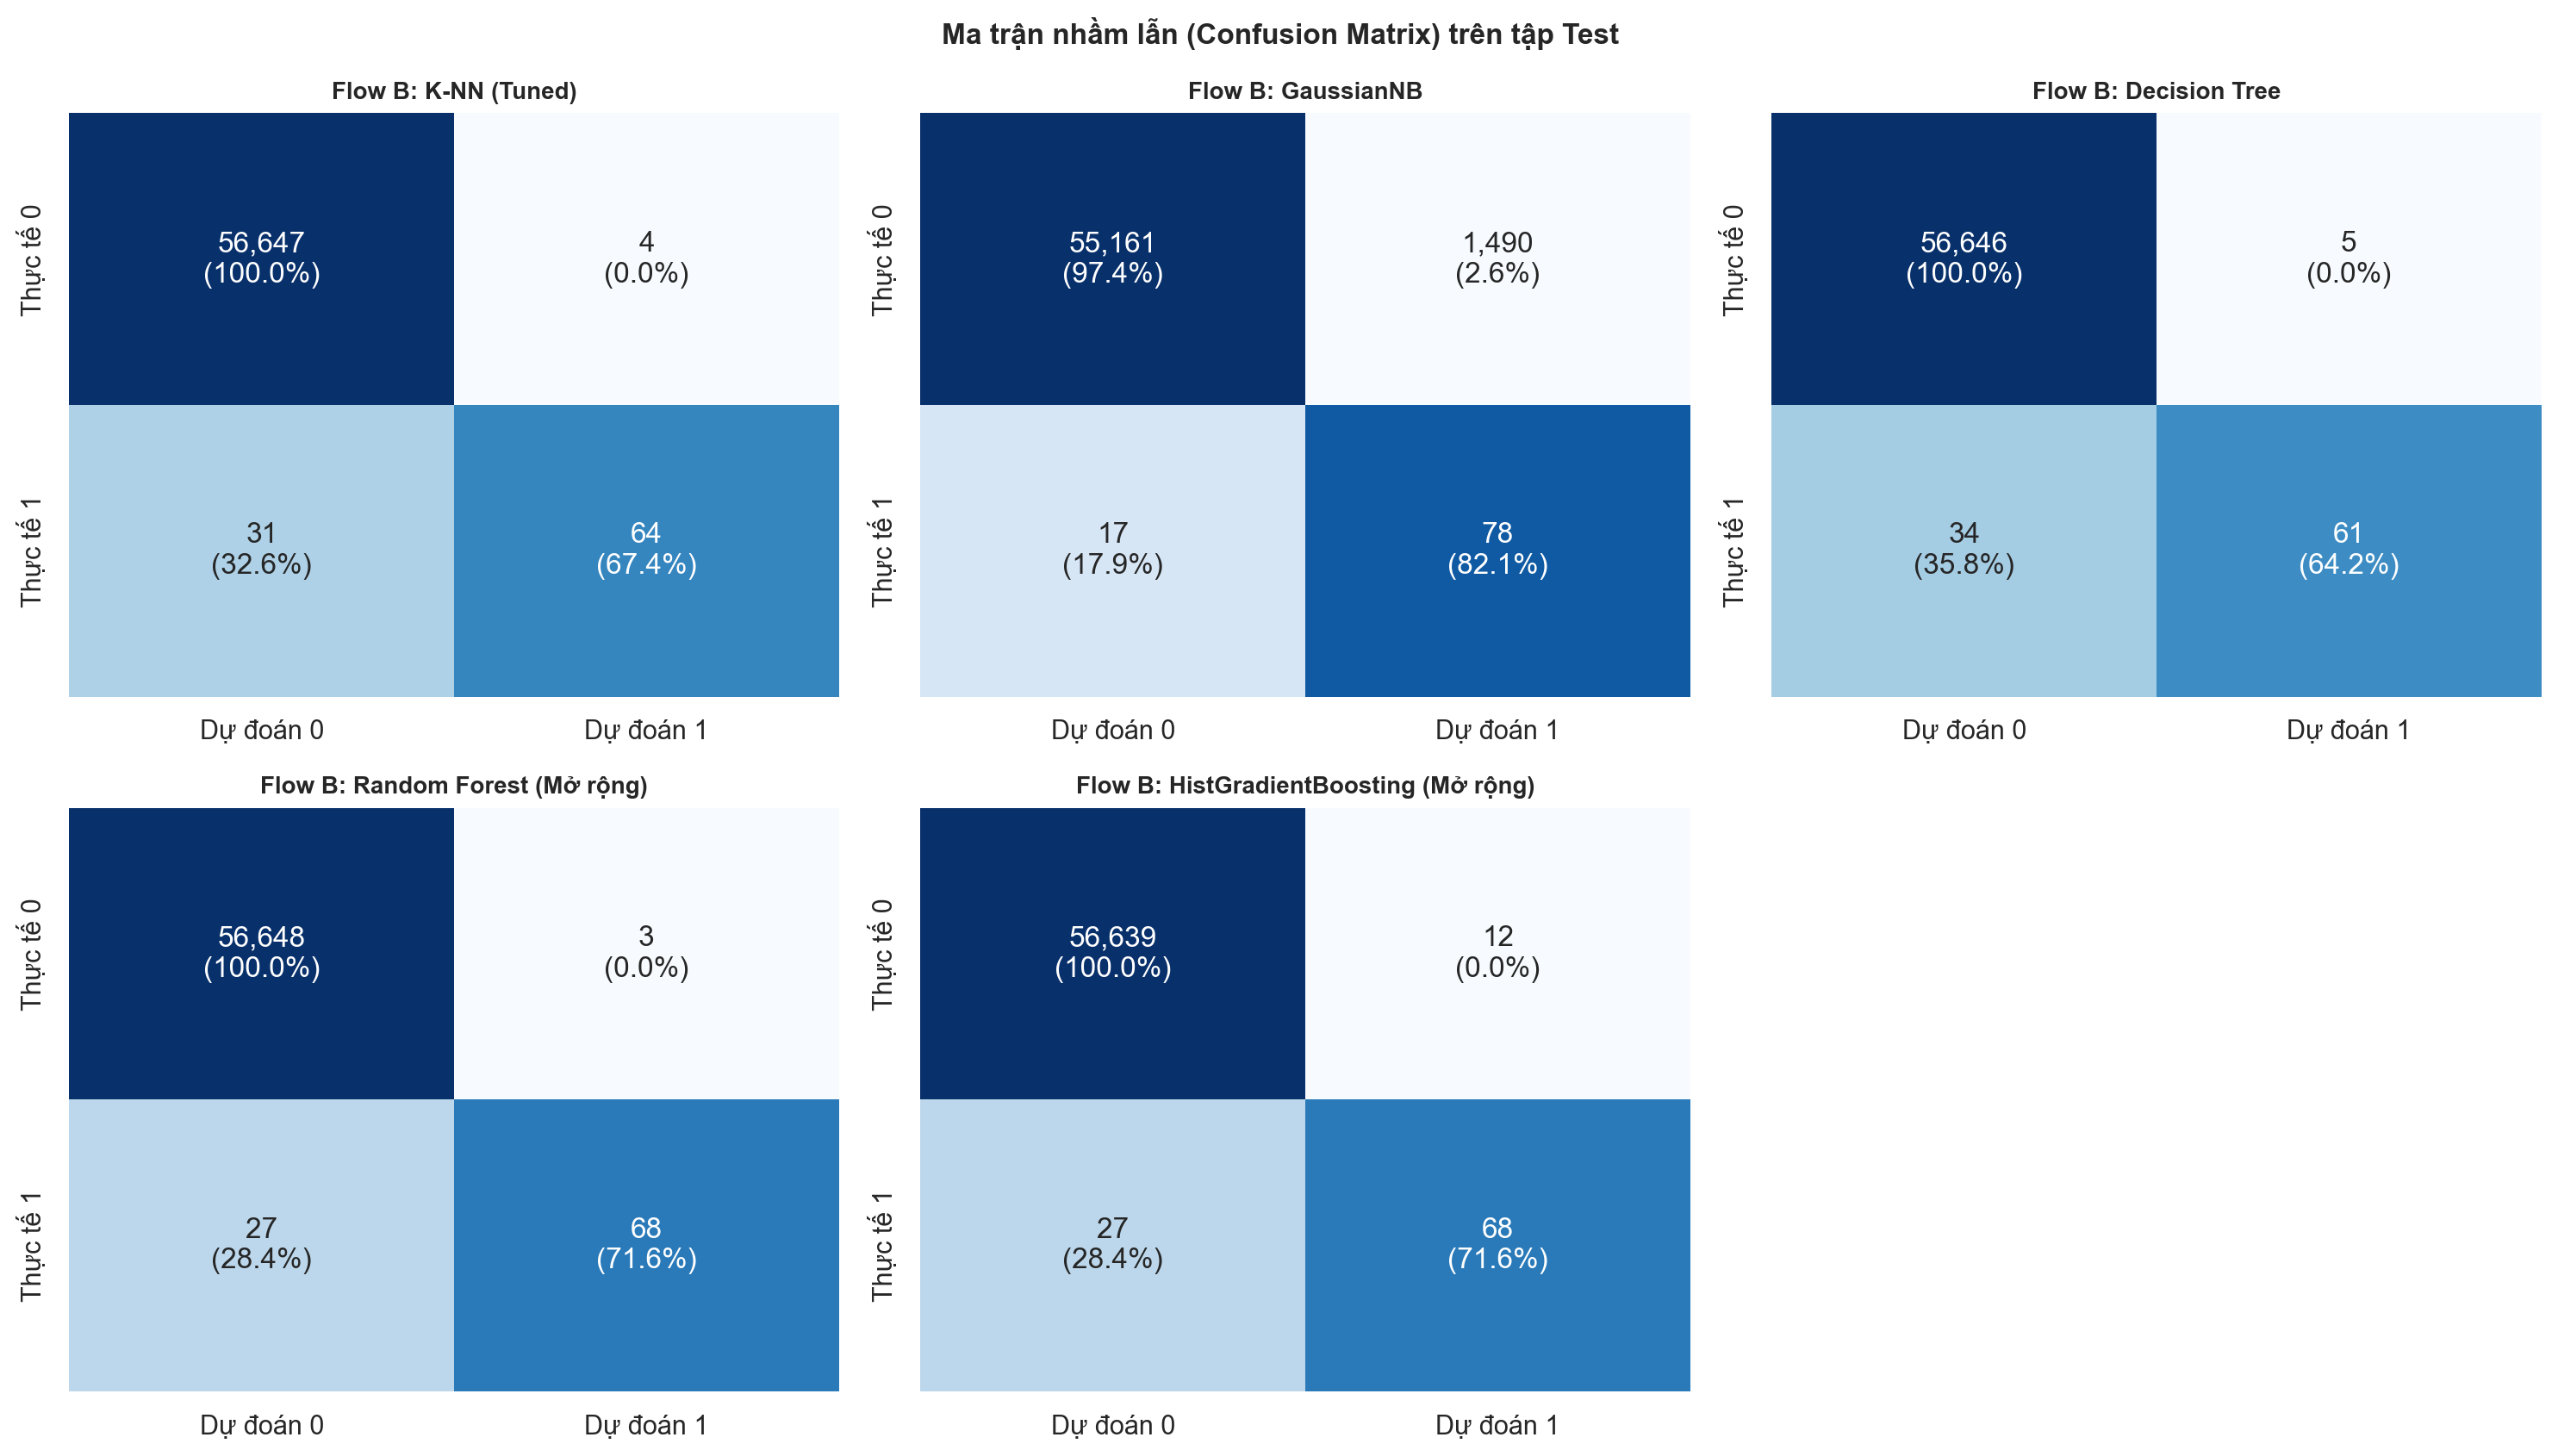

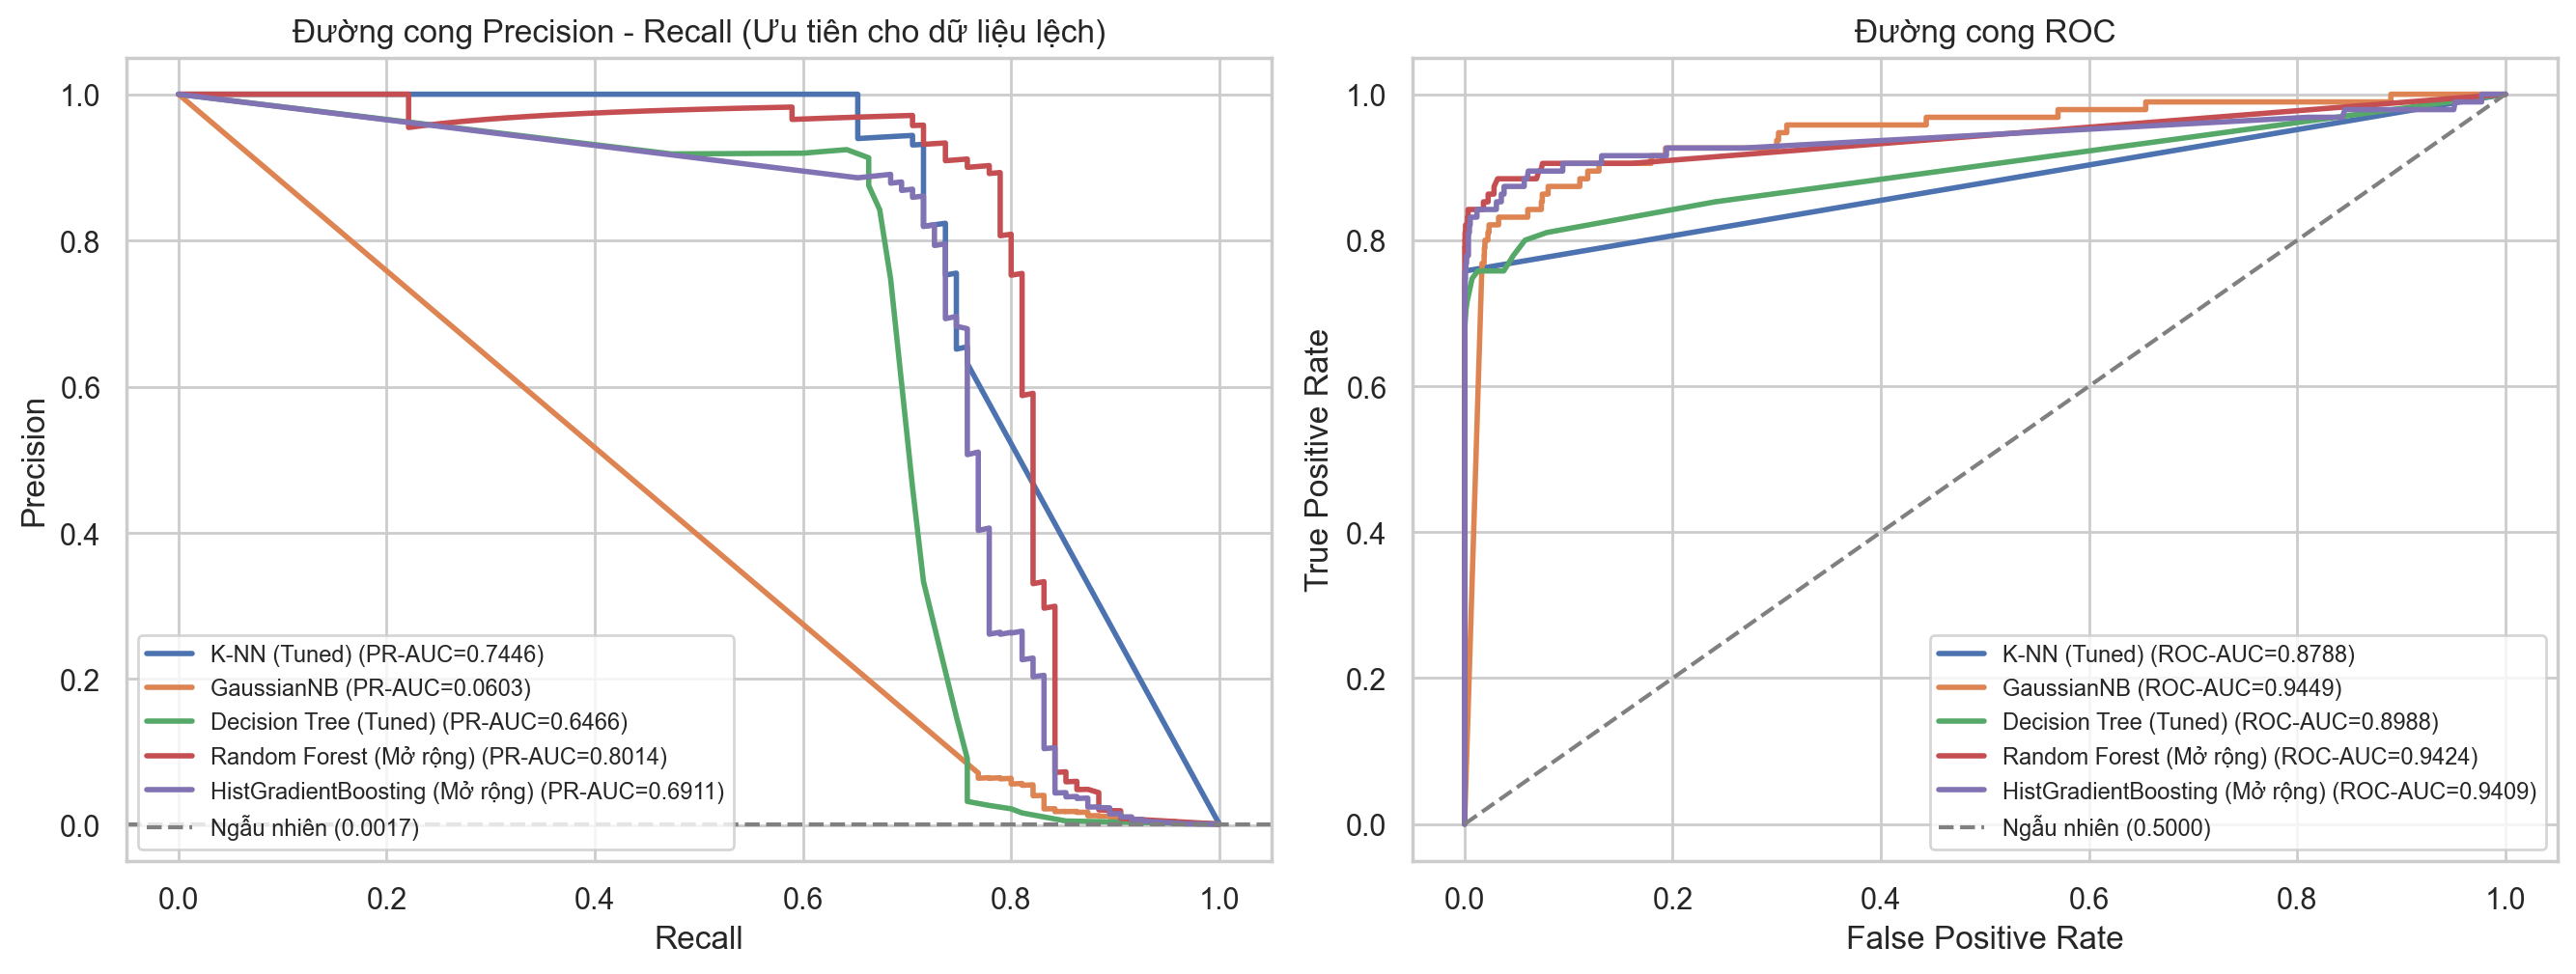

In [4]:
for fname in ["pipeline_overview.png", "flow_a_vs_flow_b.png", "confusion_matrices_flow_b.png", "pr_roc_curves_flow_b.png"]:
    p = PROJECT_ROOT / "outputs" / "figures" / fname
    if p.is_file():
        display(Image(filename=str(p)))

### Tổng kết thực nghiệm
- **Thay đổi cách chuẩn bị dữ liệu có tác động rõ rệt:** Khử trùng lặp giúp đánh giá trung thực không bị rò rỉ; chuẩn hóa quyết định sự sống còn của K-NN (`F1: 0.0594 -> 0.8000+`); biến đổi `PowerTransformer` giúp giảm 533 cảnh báo giả cho GaussianNB (`1,567 -> 1,034` FP khi kết hợp tuning ngưỡng).
- **Mô hình khuyến nghị:** Trong nhóm thuật toán học phần, **`K-NN (k=3, weights=distance)`** cho hiệu năng cân bằng nhất (`F1=0.8000, PR-AUC=0.7446`), nhưng chi phí suy luận chậm (~9.1s) hơn **`Decision Tree (Tuned)`** (`0.006s`, `F1=0.7578`). Khi mở rộng sang **`Random Forest (Mở rộng, threshold=0.55)`**, nhóm đạt đỉnh **`F1=0.8193, PR-AUC=0.8014`** với tốc độ suy luận chỉ `0.063s`.